In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd

In [3]:
synthetic_hpi_py = pd.read_parquet('../data/for_thesis/synthetic_hpi_paraguay.parquet')

In [4]:
synthetic_hpi_py.head()

,Year,HPI,ci_lower,ci_upper
0,2010.0,100.0000,100.0000,100.0000
1,2011.0,103.1663,101.5192,104.6133
2,2012.0,105.8241,102.4004,108.5608
3,2013.0,110.2126,105.2752,114.5991
4,2014.0,116.8474,110.1504,123.0712


### Calculate log returns and final volatility

In [5]:
def calcular_metricas(df):
    # Filtrar columnas necesarias
    df = df[['Year', 'HPI']].dropna()

    # Calcular retorno logarítmico ln(rₜ)
    df['ln_r'] = np.log(df['HPI'] / df['HPI'].shift(1))

    # Eliminar el primer año (no tiene retorno)
    df = df.dropna().reset_index(drop=True)

    # Calcular media de los retornos
    mu = df['ln_r'].mean()

    # Desviación respecto a la media
    df['desviacion'] = df['ln_r'] - mu

    # Cuadrado de la desviación
    df['desviacion_cuadrado'] = df['desviacion'] ** 2

    # Suma de los cuadrados
    suma_cuadrados = df['desviacion_cuadrado'].sum()

    # Varianza (n = número de años - 1)
    varianza = suma_cuadrados / (len(df) - 1)

    # Volatilidad
    volatilidad = np.sqrt(varianza)

    # Agregar fila resumen
    resumen = pd.DataFrame({
        'Año': ['Suma', 'Varianza', 'Volatilidad'],
        'HPI': ['-', '-', '-'],
        'Retorno ln(rₜ)': ['-', '-', '-'],
        'Desviación (rₜ-μ)': ['-', '-', '-'],
        '(rₜ-μ)²': [suma_cuadrados, varianza, volatilidad]
    })

    # Renombrar columnas para presentación
    df.rename(columns={
        'Year': 'Año',
        'ln_r': 'Retorno ln(rₜ)',
        'desviacion': 'Desviación (rₜ-μ)',
        'desviacion_cuadrado': '(rₜ-μ)²'
    }, inplace=True)

    # Concatenar resultados
    resultado = pd.concat([df, resumen], ignore_index=True)

    return resultado


In [6]:
volatility_df = calcular_metricas(synthetic_hpi_py)

In [7]:
volatility_df

,Año,HPI,Retorno ln(rₜ),Desviación (rₜ-μ),(rₜ-μ)²
0,2011.0,103.1663,0.031172,-0.019573,0.000383
1,2012.0,105.8241,0.025436,-0.025309,0.000641
2,2013.0,110.2126,0.040633,-0.010112,0.000102
3,2014.0,116.8474,0.058458,0.007712,0.000059
4,2015.0,124.0019,0.059428,0.008683,0.000075
5,2016.0,131.1596,0.056118,0.005373,0.000029
6,2017.0,139.4378,0.061204,0.010459,0.000109
7,2018.0,144.5974,0.036335,-0.01441,0.000208
8,2019.0,151.6263,0.047466,-0.00328,0.000011
9,2020.0,159.1141,0.048203,-0.002543,0.000006


In [8]:
volatility_df.to_csv('../data/for_thesis/volatility_for_gbm.csv')

### Calculate the drift

In [4]:
def estimate_drift(hpi_series):
    """
    Estima el drift (mu) para un modelo GBM a partir de una serie de precios.

    Parámetros:
    - hpi_series: pandas Series con valores del House Price Index ordenados por fecha

    Retorna:
    - mu: valor estimado del drift
    """
    # Asegurarse de que los valores estén ordenados por fecha
    hpi_series = hpi_series.sort_index()

    # Calcular log-retornos
    log_returns = np.log(hpi_series / hpi_series.shift(1)).dropna()

    # Calcular drift como promedio de log-retornos
    mu = log_returns.mean()

    return mu

In [5]:
mu = estimate_drift(synthetic_hpi_py['HPI'])
print(mu)

0.05074513819929498


In [6]:
def estimate_drift_table(hpi_series):
    """
    Estima el drift (mu) para un modelo GBM y devuelve la tabla de log-retornos.

    Parámetros:
    - hpi_series: pandas Series con valores del House Price Index ordenados por fecha

    Retorna:
    - log_returns_df: DataFrame con año y retorno logarítmico
    - mu: valor estimado del drift
    """
    # Asegurarse de que los valores estén ordenados por fecha
    hpi_series = hpi_series.sort_index()

    # Calcular log-retornos
    log_returns = np.log(hpi_series / hpi_series.shift(1)).dropna()

    # Crear tabla con año y log-retorno
    log_returns_df = pd.DataFrame({
        'Year': log_returns.index,
        'Log_Return': log_returns.values
    })

    # Calcular drift como promedio de log-retornos
    mu = log_returns.mean()

    return log_returns_df.round(4), round(mu, 4)

In [8]:
tabla_retornos, drift = estimate_drift_table(synthetic_hpi_py['HPI'])
print(tabla_retornos)
print("Drift estimado (μ):", drift)

    Year  Log_Return
0      1      0.0312
1      2      0.0254
2      3      0.0406
3      4      0.0585
4      5      0.0594
5      6      0.0561
6      7      0.0612
7      8      0.0363
8      9      0.0475
9     10      0.0482
10    11      0.0912
11    12      0.0851
12    13      0.0202
13    14      0.0495
Drift estimado (μ): 0.0507


In [9]:
def estimate_drift_table(df_hpi, year_column='Year', hpi_column='HPI'):
    """
    Estima el drift (mu) para un modelo GBM y devuelve la tabla de log-retornos.

    Parámetros:
    - df_hpi: DataFrame con columnas de año y HPI
    - year_column: nombre de la columna que contiene los años
    - hpi_column: nombre de la columna que contiene los valores del HPI

    Retorna:
    - log_returns_df: DataFrame con año y retorno logarítmico
    - mu: valor estimado del drift
    """
    # Ordenar por año
    df_hpi = df_hpi.sort_values(by=year_column)

    # Calcular log-retornos
    hpi_series = df_hpi[hpi_column]
    log_returns = np.log(hpi_series / hpi_series.shift(1)).dropna()

    # Alinear años (excluye el primero porque no tiene retorno)
    aligned_years = df_hpi[year_column].iloc[1:].values

    # Crear tabla con año y log-retorno
    log_returns_df = pd.DataFrame({
        'Year': aligned_years,
        'Log_Return': log_returns.values
    })

    # Calcular drift como promedio de log-retornos
    mu = log_returns.mean()

    return log_returns_df.round(4), round(mu, 4)

In [10]:
tabla_retornos, drift = estimate_drift_table(synthetic_hpi_py)
print(tabla_retornos)
print("Drift estimado (μ):", drift)

      Year  Log_Return
0   2011.0      0.0312
1   2012.0      0.0254
2   2013.0      0.0406
3   2014.0      0.0585
4   2015.0      0.0594
5   2016.0      0.0561
6   2017.0      0.0612
7   2018.0      0.0363
8   2019.0      0.0475
9   2020.0      0.0482
10  2021.0      0.0912
11  2022.0      0.0851
12  2023.0      0.0202
13  2024.0      0.0495
Drift estimado (μ): 0.0507


In [11]:
tabla_retornos.to_csv('../data/for_thesis/log_return_table.csv')

### Calculate the volatility

In [8]:
def estimate_volatility(hpi_series):
    """
    Estima la volatilidad (sigma) para un modelo GBM a partir de una serie de precios.

    Parámetros:
    - hpi_series: pandas Series con valores del House Price Index ordenados por fecha

    Retorna:
    - sigma: valor estimado de la volatilidad
    """
    # Asegurarse de que los valores estén ordenados por fecha
    hpi_series = hpi_series.sort_index()

    # Calcular log-retornos
    log_returns = np.log(hpi_series / hpi_series.shift(1)).dropna()

    # Calcular volatilidad como desviación estándar de los log-retornos
    sigma = log_returns.std()

    return sigma

In [9]:
sigma = estimate_volatility(synthetic_hpi_py['HPI'])
print(sigma)

0.02032215539194366


### Run the motion

In [11]:
def geometric_brownian_motion(S0, mu, sigma, T, dt, n_simulations):
    """
    Generate price paths using Geometric Brownian Motion (GBM)
        
    Parameters:
    - S0: Initial price
    - mu: Drift (expected return)
    - sigma: Volatility
    - T: Time horizon (years)
    - dt: Time step
    - n_simulations: Number of simulation paths
        
    Returns:
    - Array of final prices for each simulation
    """
    n_steps = int(T / dt)
    dt_sqrt = np.sqrt(dt)
        
    # Generate random shocks
    random_shocks = np.random.normal(0, 1, (n_simulations, n_steps))
        
    # Initialize price array
    prices = np.zeros((n_simulations, n_steps + 1))
    prices[:, 0] = S0
        
    # Calculate price evolution
    for t in range(1, n_steps + 1):
        prices[:, t] = prices[:, t-1] * np.exp(
            (mu - 0.5 * sigma**2) * dt + sigma * dt_sqrt * random_shocks[:, t-1]
        )
        
    return prices  # Return final prices

In [26]:
paths = geometric_brownian_motion(200000, mu, sigma, 1, 1/12, 12)

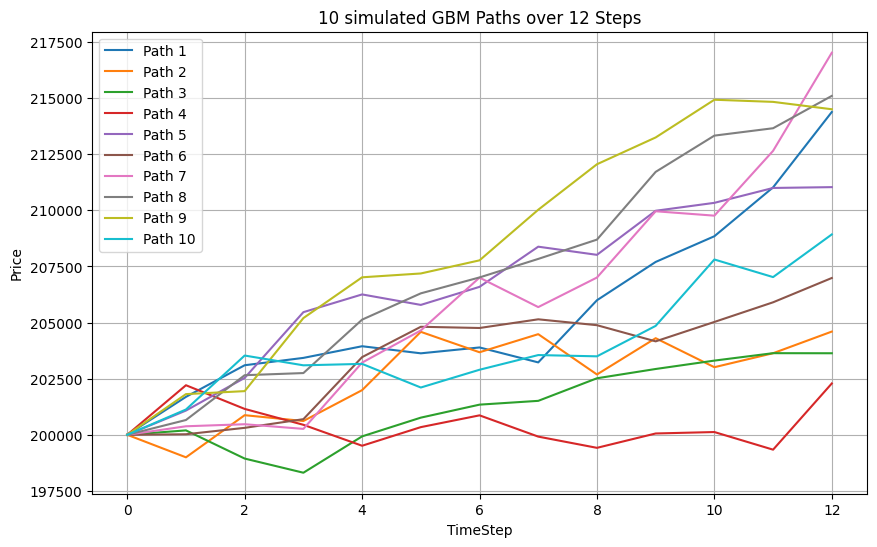

In [27]:
plt.figure(figsize=(10,6))
for i in range(10):
    plt.plot(paths[i], label=f"Path {i+1}")
plt.title("10 simulated GBM Paths over 12 Steps")
plt.xlabel("TimeStep")
plt.ylabel("Price")
plt.grid(True)
plt.legend()
plt.show()

In [14]:
paths2 = geometric_brownian_motion(100, mu, sigma, 1, 1/50, 10)

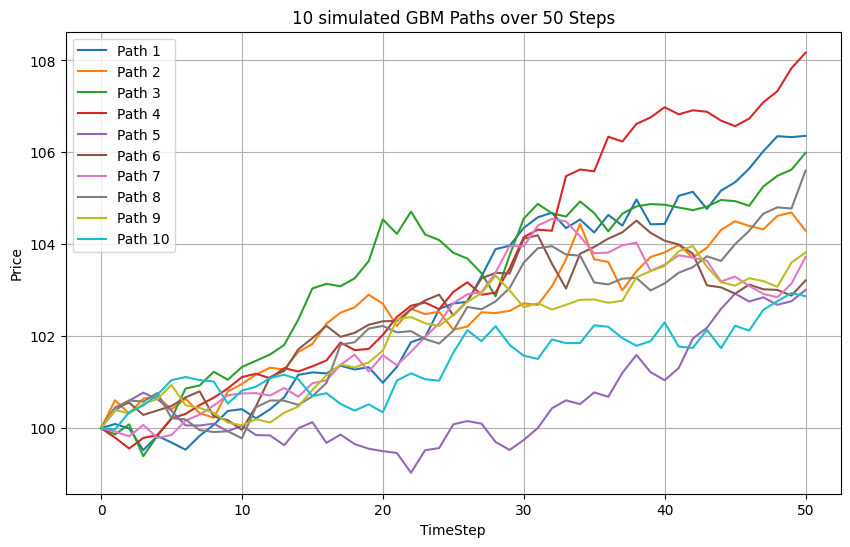

In [15]:
plt.figure(figsize=(10,6))
for i in range(10):
    plt.plot(paths2[i], label=f"Path {i+1}")
plt.title("10 simulated GBM Paths over 50 Steps")
plt.xlabel("TimeStep")
plt.ylabel("Price")
plt.grid(True)
plt.legend()
plt.show()

### Run an example of the motion

In [9]:
paths = geometric_brownian_motion(100, 0.05, 0.2, 1, 1/50, 10)

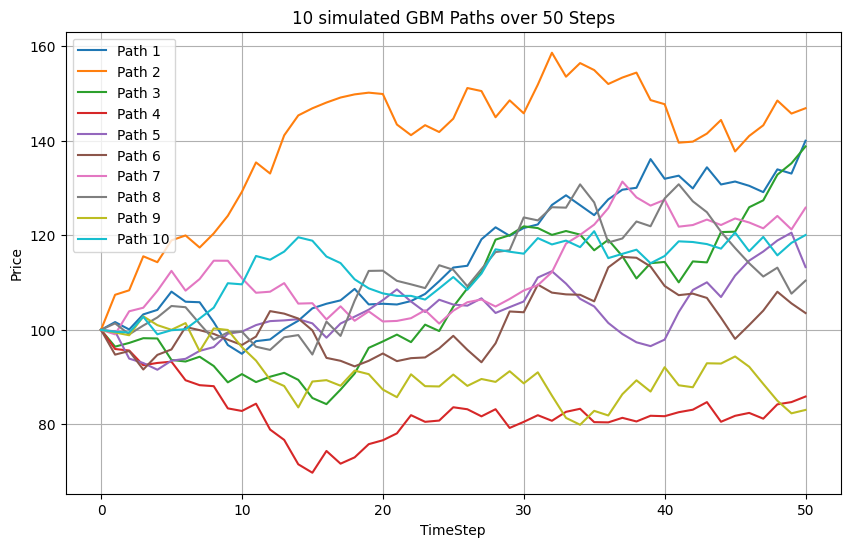

In [10]:
plt.figure(figsize=(10,6))
for i in range(10):
    plt.plot(paths[i], label=f"Path {i+1}")
plt.title("10 simulated GBM Paths over 50 Steps")
plt.xlabel("TimeStep")
plt.ylabel("Price")
plt.grid(True)
plt.legend()
plt.show()